# Lab 1 – Đọc, kiểm tra và hiển thị ảnh (OpenCV)

**Người thực hiện:** TV1  
**Branch:** `feature/lab01-read-display`  
**Source:** `lab_1/src/image_io.py`

## Mục tiêu
Xây dựng bước đầu của pipeline: đọc ảnh bằng OpenCV, kiểm tra ảnh có đọc được không, lấy thông tin ảnh (shape, kích thước, channel, dtype) và hiển thị ảnh đúng màu.

## 1. Import và cấu hình đường dẫn
Dùng đường dẫn tương đối để máy nào clone về cũng chạy được.

In [1]:
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt

sys.path.append(str(Path("..") / "src"))
import image_io as io

from image_io import find_input_image
INPUT = find_input_image("06_animal_lion.jpg")   # ảnh trong data/input (tự chọn ảnh khác nếu không thấy)
print("OpenCV version:", cv2.__version__)
print("Ảnh tồn tại:", INPUT.exists())

OpenCV version: 4.13.0
Ảnh tồn tại: True


## 2. Đọc ảnh bằng `cv2.imread()`
`cv2.imread(path)` **không báo lỗi** khi đường dẫn sai mà trả về `None`, nên phải kiểm tra trước khi xử lý tiếp.

In [2]:
image = io.read_image(INPUT)

if image is None:
    print("Không đọc được ảnh, kiểm tra lại đường dẫn:", INPUT)
else:
    print("Đọc ảnh thành công")

Đọc ảnh thành công


### Kiểm tra trường hợp lỗi
Thử đọc một file không tồn tại để xác nhận `imread` trả về `None`.

In [3]:
bad = io.read_image("../data/input/khong_ton_tai.jpg")
print("Kết quả khi đọc file không tồn tại:", bad)
print("bad is None ->", bad is None)

Kết quả khi đọc file không tồn tại: None
bad is None -> True


## 3. Lấy thông tin ảnh

In [4]:
info = io.get_image_info(image)

print("Shape   :", info["shape"])
print("Height  :", info["height"])
print("Width   :", info["width"])
print("Channels:", info["channels"])
print("Dtype   :", info["dtype"])

Shape   : (256, 256, 3)
Height  : 256
Width   : 256
Channels: 3
Dtype   : uint8


**Giải thích:**
- `shape` có dạng `(height, width, channels)`: số hàng, số cột, số kênh màu.
- Ảnh màu có 3 kênh; `dtype = uint8` nghĩa là mỗi pixel mỗi kênh là số nguyên 0–255.
- Ảnh số là một lưới pixel, mỗi pixel là một vector 3 giá trị.

In [5]:
# Xem giá trị của một pixel: image[y, x] (hàng trước, cột sau)
y, x = image.shape[0] // 2, image.shape[1] // 2   # pixel ở giữa ảnh
b, g, r = image[y, x]
print(f"Pixel tại (x={x}, y={y}) -> B={b}, G={g}, R={r}")

Pixel tại (x=128, y=128) -> B=90, G=112, R=147


## 4. Hiển thị ảnh
### 4.1 Hiển thị SAI màu (không đổi BGR → RGB)
Matplotlib hiểu mảng là RGB, trong khi OpenCV lưu BGR nên kênh đỏ và xanh dương bị đảo.

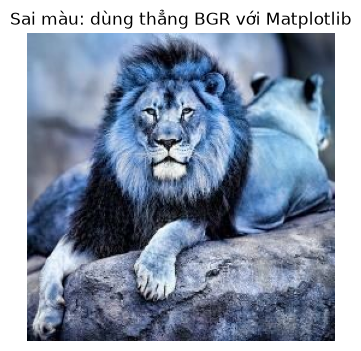

In [6]:
io.show_image(image, "Sai màu: dùng thẳng BGR với Matplotlib", is_bgr=False)

### 4.2 Hiển thị ĐÚNG màu (đổi BGR → RGB)

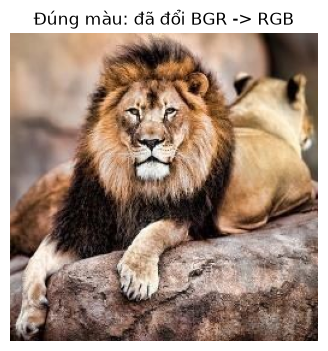

In [7]:
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
plt.figure(figsize=(7, 4))
plt.imshow(image_rgb)
plt.title("Đúng màu: đã đổi BGR -> RGB")
plt.axis("off")
plt.show()

### 4.3 So sánh hai cách hiển thị

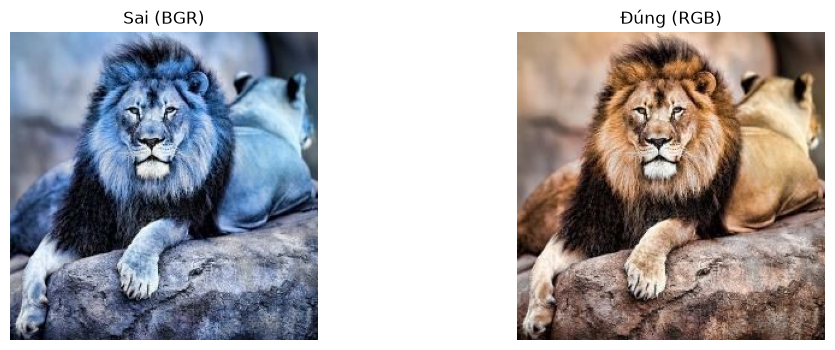

In [8]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1); plt.imshow(image);     plt.title("Sai (BGR)"); plt.axis("off")
plt.subplot(1, 2, 2); plt.imshow(image_rgb); plt.title("Đúng (RGB)"); plt.axis("off")
plt.savefig("../result/figures/read_display_bgr_vs_rgb.png", dpi=150, bbox_inches="tight")
plt.show()

### 4.4 Tách từng kênh màu
Giúp thấy rõ thứ tự kênh trong mảng của OpenCV.

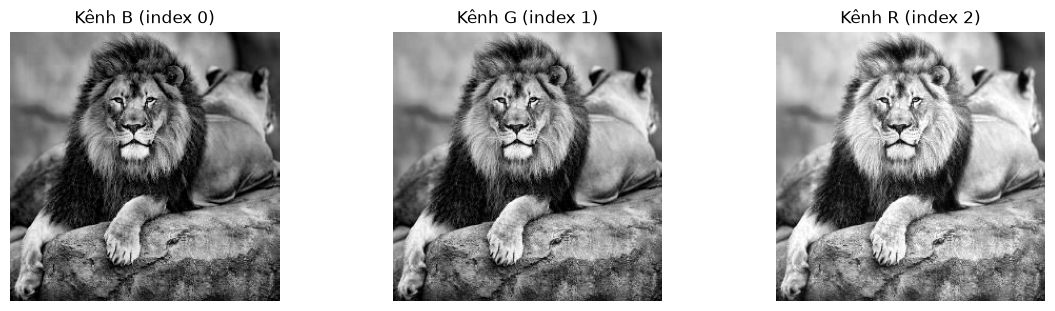

In [9]:
b, g, r = cv2.split(image)   # thứ tự trả về là B, G, R

plt.figure(figsize=(14, 3.5))
for i, (ch, name) in enumerate([(b, "Kênh B (index 0)"), (g, "Kênh G (index 1)"), (r, "Kênh R (index 2)")], 1):
    plt.subplot(1, 3, i); plt.imshow(ch, cmap="gray"); plt.title(name); plt.axis("off")
plt.show()

## 5. Giải thích: vì sao OpenCV mặc định dùng BGR?
Đây là quy ước lịch sử: khi OpenCV ra đời, nhiều camera và định dạng ảnh phổ biến lúc đó (như BMP) lưu pixel theo thứ tự B-G-R, nên thư viện chọn BGR và giữ nguyên để tương thích ngược. Các thư viện khác như Matplotlib hay Pillow dùng RGB, vì vậy khi chuyển ảnh giữa các thư viện phải đổi bằng `cv2.cvtColor(img, cv2.COLOR_BGR2RGB)`.

## 6. Nhận xét
- `cv2.imread()` trả về `None` thay vì ném lỗi, nên luôn phải kiểm tra `image is None` để tránh lỗi khó hiểu ở các bước sau.
- `shape` theo thứ tự `(height, width, channels)`, khác với Pillow dùng `size = (width, height)`.
- Quên đổi BGR → RGB khi hiển thị bằng Matplotlib làm màu bị đảo (vùng xanh dương bị hiện thành cam/đỏ), dễ gây nhầm lẫn khi kiểm tra kết quả.
- Ảnh dùng `uint8` nên mọi phép tính trên pixel cần chú ý tràn số (ví dụ 250 + 10 sẽ quay vòng thay vì thành 260).